<a href="https://colab.research.google.com/github/heesuh98/BIcoding2/blob/main/R_SNUH_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction

```{r intro, eval = FALSE}

  # Differential expression analysis is used to determine which genes are significantly influenced by the experimental conditions.
  # we performed differential expression analysis using the GSE70466 dataset, which compares two distinct human prostate cell types: androgen-sensitive prostate adenocarcinoma cells (LNCaP) and normal prostate epithelial cells (PrEC).
  # This comparison allows us to investigate which genes are transcriptionally altered in association with prostate cancer progression, particularly in the context of androgen sensitivity.

```

In [245]:
# BiocManager 설치
if (!requireNamespace("BiocManager", quietly = TRUE))
    install.packages("BiocManager")

# CRAN 패키지 설치
install.packages(c("dplyr", "ggplot2", "tibble", "pheatmap"))

# Bioconductor 패키지 설치
BiocManager::install(c("DESeq2", "apeglm"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.21 (BiocManager 1.30.26), R 4.5.1 (2025-06-13)

Warning message:
“package(s) not installed when version(s) same as or greater than current; use
  `force = TRUE` to re-install: 'DESeq2' 'apeglm'”
Old packages: 'textshaping'



Differential Gene Expression Analysis with the RNA-seq Data

In [95]:
library(dplyr)
library(ggplot2)
library(tibble)
library(DESeq2)
library(pheatmap)
library(apeglm)

# Part 1: Data preprocessing and exploratory data analysis

```{r part1, eval = FALSE}

  # Load the expression and metadata from the GSE70466 data.
  # Yon can access the data via following URL: https://bit.ly/46CLeXa
  # Create the data object for the Differential Gene Expression (DGE) analysis.

```

In [258]:
# Load the expression and metadata from the GSE70466 data
# GSE70466 data : NCBI(미국 국립생물정보센터)의 GEO 데이터로 RNA-Seq gene expression datasets



expr_file <- "/content/SNUH/GSE70466-expression.txt"
meta_file <- "/content/SNUH/GSE70466-metadata.txt"

# Count matrix
expr <- read.table(expr_file, header=TRUE, sep="\t", row.names = 1)
expr_t <- t(expr)
expr_t_df <- as.data.frame(expr_t)
expr_t_df$Gene <- rownames(expr_t_df)
expr_df <- expr_t_df[, c(ncol(expr_t_df), 1:(ncol(expr_t_df)-1))]
rownames(expr_df) <- NULL

# Metadata
meta <- read.table(meta_file, header=TRUE, sep="\t")
colnames(meta) <- gsub(" ", "_", colnames(meta))
dim(expr_df)
dim(meta)

[1] 35238     7

[1] 6 4

In [97]:
head(expr_df)

,Gene,GSM1778901,GSM1778903,GSM1778904,GSM1778905,GSM1778906,GSM1778907
,<chr>,<int>,<int>,<int>,<int>,<int>,<int>
1,A1BG,60,110,100,22,48,12
2,A1CF,7,3,5,1,5,2
3,A2M,7,1,4,3,7,6
4,A2ML1,106,142,164,236,168,279
5,A2MP1,6,1,7,0,2,2
6,A3GALT2,1,2,1,0,0,0


In [259]:
meta

Sample_geo_accession,Sample.Title,cell.line,cell.type
<chr>,<chr>,<chr>,<chr>
GSM1778901,LNCaP_1_GRCh37_74,LNCaP,androgen-sensitive human prostate adenocarcinoma (LNCaP)
GSM1778903,LNCaP_2_GRCh37_74,LNCaP,androgen-sensitive human prostate adenocarcinoma (LNCaP)
GSM1778904,LNCaP_3_GRCh37_74,LNCaP,androgen-sensitive human prostate adenocarcinoma (LNCaP)
GSM1778905,PrEC_1_GRCh37_74,PrEC,normal prostate epithelial cells (PrEC)
GSM1778906,PrEC_2_GRCh37_74,PrEC,normal prostate epithelial cells (PrEC)
GSM1778907,PrEC_3_GRCh37_74,PrEC,normal prostate epithelial cells (PrEC)


# Part 2: Quality Control

```{r part2, eval = FALSE}

  # Check total read counts per gene and perform gene-level filtering.

  # Execute sample-level QC using Principal Component Analysis (PCA) and hierarchical clustering methods.

```

## Part 2.1 Check total read counts per gene
```{r part2.1, eval = FALSE}

  # total read count 분포를 확인한다.
  # 최소 3개의 샘플에서 read count가 10을 넘는 샘플로 유전자 filtering한다.
  # read count의 경우 대부분의 논문에서 10 권장하므로 raw data의 히스토그램에서 x=10, x=20 선을 그어보고 데이터 분포를 시각적으로 확인함.

```

Warning message in scale_x_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 11386 rows containing non-finite outside the scale range
(`stat_bin()`).”


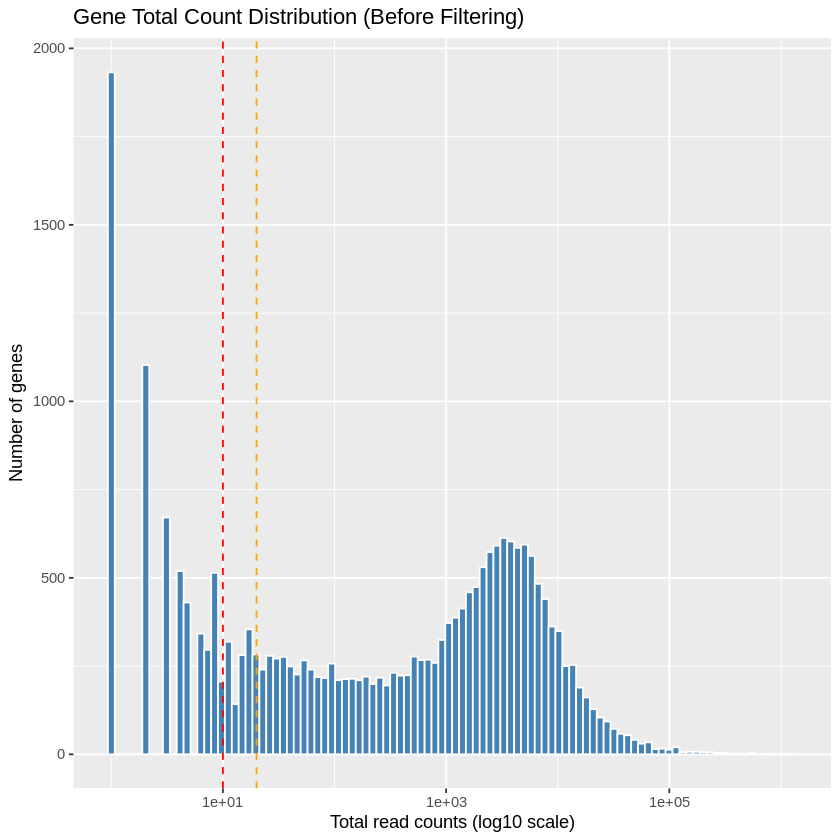

In [239]:
#2.1 raw data의 total read count 분포 확인
ggplot(gene_counts_df, aes(x = total_counts)) +
  geom_histogram(bins = 100, fill = "steelblue", color = "white") +
  scale_x_log10() +
  geom_vline(xintercept = 10, linetype = "dashed", color = "red") +
  geom_vline(xintercept = 20, linetype = "dashed", color = "orange") +
  labs(title = "Gene Total Count Distribution (Before Filtering)",
       x = "Total read counts (log10 scale)",
       y = "Number of genes")


In [240]:
# 조건 설정
min_samples <- 3       # 최소 몇 개 샘플에서
count_threshold <- 10  # count > 10 조건

# 각 유전자별로 count > 10 인 샘플 수 계산
pass_counts <- rowSums(expr_matrix > count_threshold)

# 조건을 만족하는 유전자만 남김
keep_genes <- names(pass_counts[pass_counts >= min_samples])
expr_filtered <- expr_matrix[keep_genes, , drop = FALSE]

cat("Before filtering:", nrow(expr_matrix), "genes\n")
cat("After filtering:", nrow(expr_filtered), "genes\n")
head(expr_filtered)

Before filtering: 35238 genes
After filtering: 14527 genes


,GSM1778901,GSM1778903,GSM1778904,GSM1778905,GSM1778906,GSM1778907
,<int>,<int>,<int>,<int>,<int>,<int>
A1BG,60,110,100,22,48,12
A2ML1,106,142,164,236,168,279
A4GALT,6,8,6,269,212,282
AAAS,647,1032,1051,1165,818,914
AACS,799,932,793,1367,1019,1213
AACSP1,98,101,105,1,5,5


Before outlier filtering: 14527 genes
After outlier filtering: 14512 genes


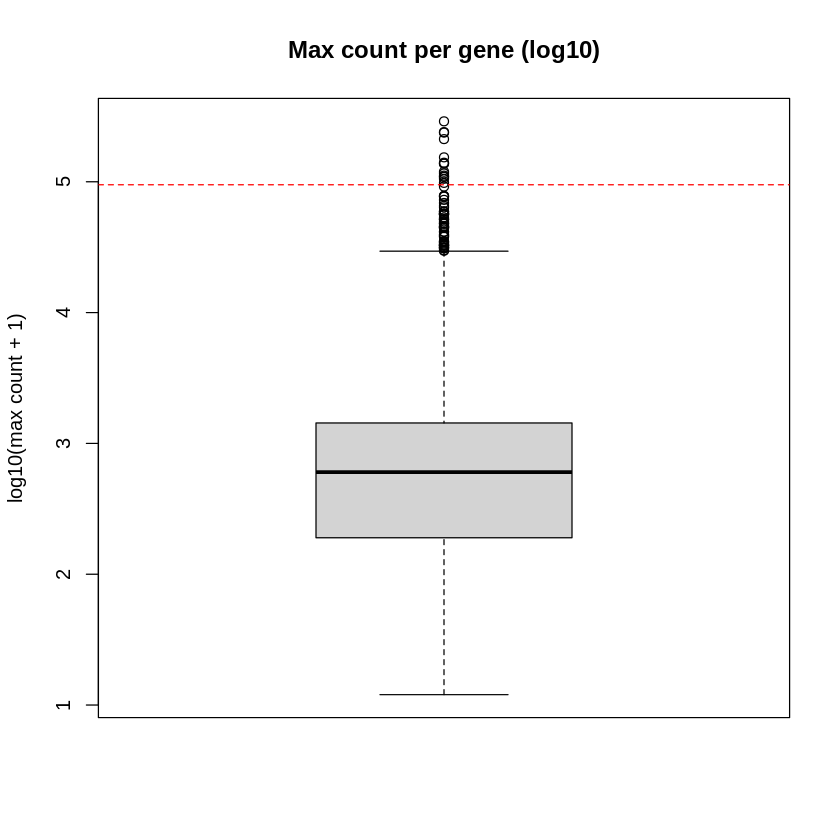

In [188]:
#outlier 확인
# 크게 차이가 나는 outlier는 없기 때문에 outlier는 제거하지 않는다.

# 유전자별로 최대 count가 너무 높은 경우 제거
max_count_per_gene <- apply(expr_filtered, 1, max)

# 상위 99.9% quantile 값 계산
upper_cutoff <- quantile(max_count_per_gene, 0.999)

# 너무 큰 값 가진 유전자 제거
final_genes <- names(max_count_per_gene[max_count_per_gene <= upper_cutoff])
expr_final <- expr_filtered[final_genes, , drop = FALSE]

# 결과 확인
cat("Before outlier filtering:", nrow(expr_filtered), "genes\n")
cat("After outlier filtering:", nrow(expr_final), "genes\n")

boxplot(log10(max_count_per_gene + 1), main = "Max count per gene (log10)",
        ylab = "log10(max count + 1)")
abline(h = log10(upper_cutoff + 1), col = "red", lty = 2)


In [100]:
# ##FILTERING 2
# min_samples <- 3           # 최소 샘플 개수
# count_threshold <- 10      # count > 10 조건
# outlier_factor <- 10       # 평균 대비 outlier 허용 배수 (필요에 따라 조정)

# # 1. 모든 샘플 count 0인 경우 제거
# nonzero_genes <- rowSums(expr_matrix > 0) > 0
# expr_matrix_nonzero <- expr_matrix[nonzero_genes, , drop = FALSE]

# # 2. count > count_threshold인 샘플 수 기준 필터링
# pass_counts <- rowSums(expr_matrix_nonzero > count_threshold)
# keep_genes_pass <- pass_counts >= min_samples
# expr_matrix_pass <- expr_matrix_nonzero[keep_genes_pass, , drop = FALSE]

# # 3. 극단적 outlier 제거 (평균 대비 특정 배수 이상인 count가 있을 경우 필터링)
# gene_means <- rowMeans(expr_matrix_pass)
# outlier_flags <- apply(expr_matrix_pass, 1, function(x) any(x > outlier_factor * mean(x)))
# expr_matrix_outlier <- expr_matrix_pass[!outlier_flags, , drop = FALSE]

# # 4. low mean normalized count 제거 (예: 평균 count가 10 미만인 유전자 제거)
# low_mean_flags <- gene_means >= count_threshold
# expr_filtered2 <- expr_matrix_outlier[low_mean_flags, , drop = FALSE]

# cat("Before filtering:", nrow(expr_matrix), "genes\n")
# cat("After filtering:", nrow(expr_filtered2), "genes\n")
# head(expr_filtered2)

Before filtering: 35238 genes
After filtering: 14378 genes


,GSM1778901,GSM1778903,GSM1778904,GSM1778905,GSM1778906,GSM1778907
,<int>,<int>,<int>,<int>,<int>,<int>
A1BG,60,110,100,22,48,12
A2ML1,106,142,164,236,168,279
A4GALT,6,8,6,269,212,282
AAAS,647,1032,1051,1165,818,914
AACS,799,932,793,1367,1019,1213
AACSP1,98,101,105,1,5,5


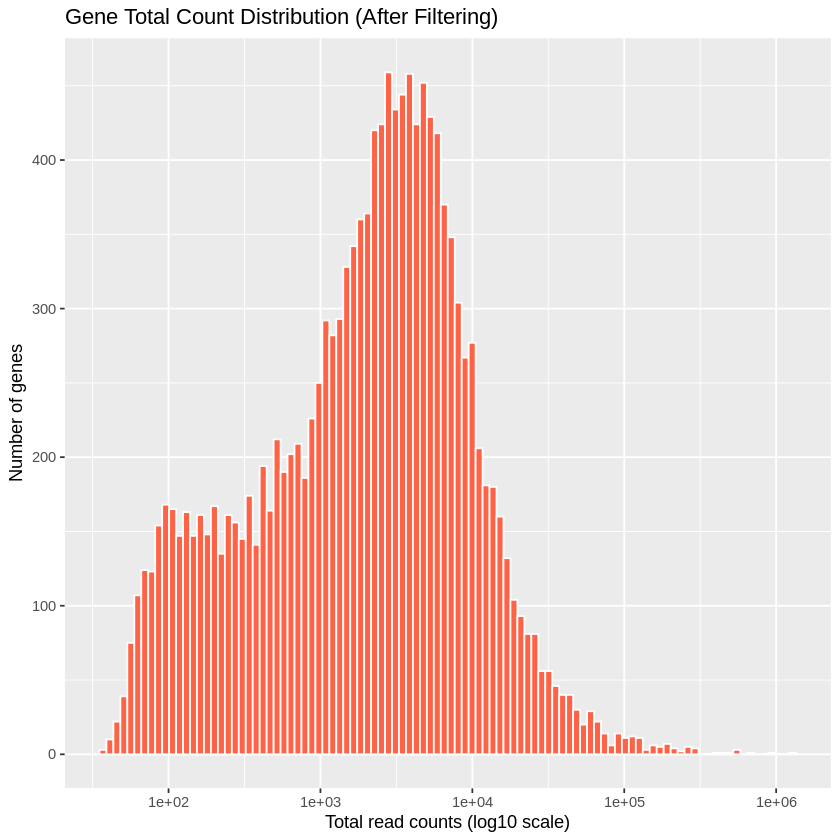

In [198]:
#Filtered data 시각화

gene_counts_df_filtered <- data.frame(
  total_counts = rowSums(expr_filtered)
)

ggplot(gene_counts_df_filtered, aes(x = total_counts)) +
  geom_histogram(bins = 100, fill = "tomato", color = "white") +
  scale_x_log10() +
  labs(title = "Gene Total Count Distribution (After Filtering)",
       x = "Total read counts (log10 scale)",
       y = "Number of genes")

#2.2 PCA

```{r part2.2, eval = FALSE}

  # Execute sample-level QC using Principal Component Analysis (PCA) and hierarchical clustering methods
  # 샘플 간 발현 패턴의 전반적인 품질 확인을 위해 PCA 분석을 수행.
  # vst() 함수를 통해 variance stabilizing transformation (VST)을 적용하여 정규화하였으며, 이를 통해 overexpress gene, sequencing depth 차이로 인한 왜곡을 최소화하였다.
  # cell.type에 따라 그룹을 나누고 데이터 품질을 확인함 -> cell.type 기준으로 명확히 분리됨
  # PCA 결과, LNCaP와 PrEC 세포 간 샘플은 주성분 1 (PC1)을 기준으로 명확히 분리되었으며,PC1은 전체 변이의 98%를 설명함. 이는 세포 유형 간의 생물학적 차이가 유전자 발현 패턴에 잘 반영되어 있음을 나타내며 데이터 품질에 큰 문제가 없음을 확인.
  # 또한 outlier 샘플은 관찰되지 않았다.

```

In [241]:
# Execute sample-level QC using Principal Component Analysis (PCA) and hierarchical clustering methods

library(DESeq2)
library(ggplot2)
library(pheatmap)
library(RColorBrewer)

dds <- DESeqDataSetFromMatrix(countData = expr_filtered,
                              colData = meta,
                              design = ~ cell.type)

vsd <- vst(dds, blind = FALSE)

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]



In [162]:
head(dds)

class: DESeqDataSet 
dim: 6 6 
metadata(1): version
assays(4): counts mu H cooks
rownames(6): A1BG A2ML1 ... AACS AACSP1
rowData names(22): baseMean baseVar ... deviance maxCooks
colnames(6): GSM1778901 GSM1778903 ... GSM1778906 GSM1778907
colData names(5): Sample_geo_accession Sample.Title cell.line cell.type
  sizeFactor

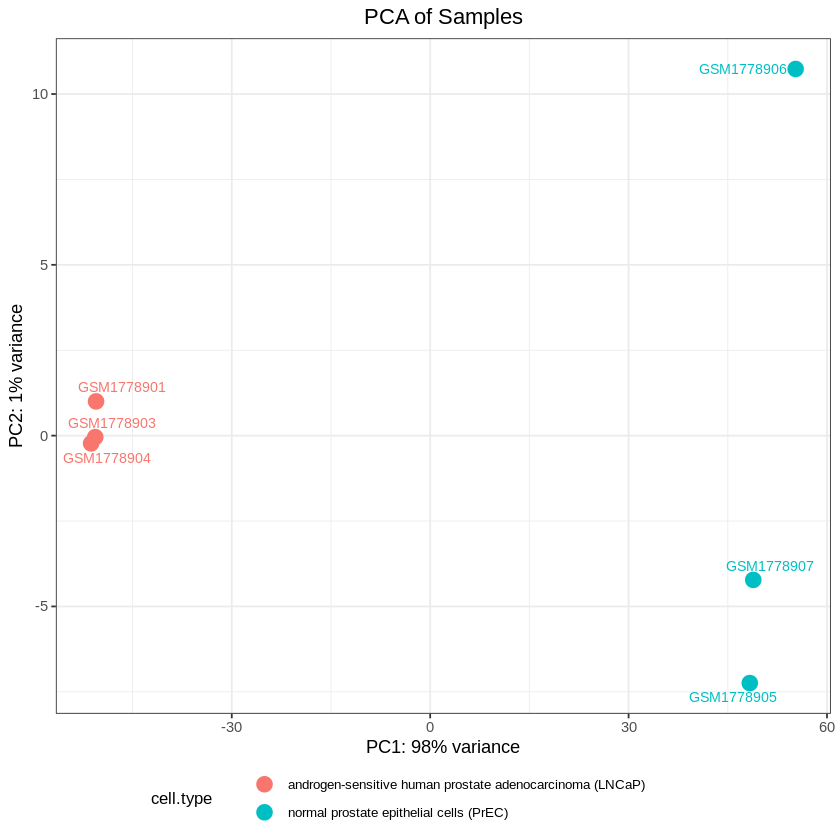

In [158]:
library(ggrepel)

ggplot(pcaData, aes(PC1, PC2, color=cell.type, label=Sample_geo_accession)) +
  geom_point(size=4) +
  geom_text_repel(size=3, box.padding = 0.3, point.padding = 0.3) +
  xlab(paste0("PC1: ", percentVar[1], "% variance")) +
  ylab(paste0("PC2: ", percentVar[2], "% variance")) +
  ggtitle("PCA of Samples") +
  theme_bw() +
  theme(
    plot.title = element_text(hjust = 0.5),        # 제목 가운데 정렬
    legend.position = "bottom",
    legend.text = element_text(size = 8),
    legend.title = element_text(size = 10),
    legend.key.width = unit(0.6, "cm"),
    legend.key.height = unit(0.4, "cm"),
    legend.box.spacing = unit(0.2, "cm")
  ) +
  guides(color = guide_legend(nrow = 2, byrow = TRUE))


#2.3 Hierarchical clustering

```{r part2.3, eval = FALSE}
# heatmap은 샘플 간 유사도(거리)를 직관적으로 보여줌.
# 샘플 간 발현 패턴의 유사성을 평가하기 위해 변환된 발현 데이터(vsd)를 기반으로 유클리드 거리를 계산.
# 이를 통해 각 샘플 간 거리를 행렬로 변환한 후, 계층적 군집화(hierarchical clustering)를 수행하였다.
# 샘플의 생물학적 그룹 정보를 명확히 시각화하기 위해, meta data 에 포함된 cell.type 정보를 바탕으로 샘플에 annotation을 추가

```


[1] "#1B9E77" "#D95F02"

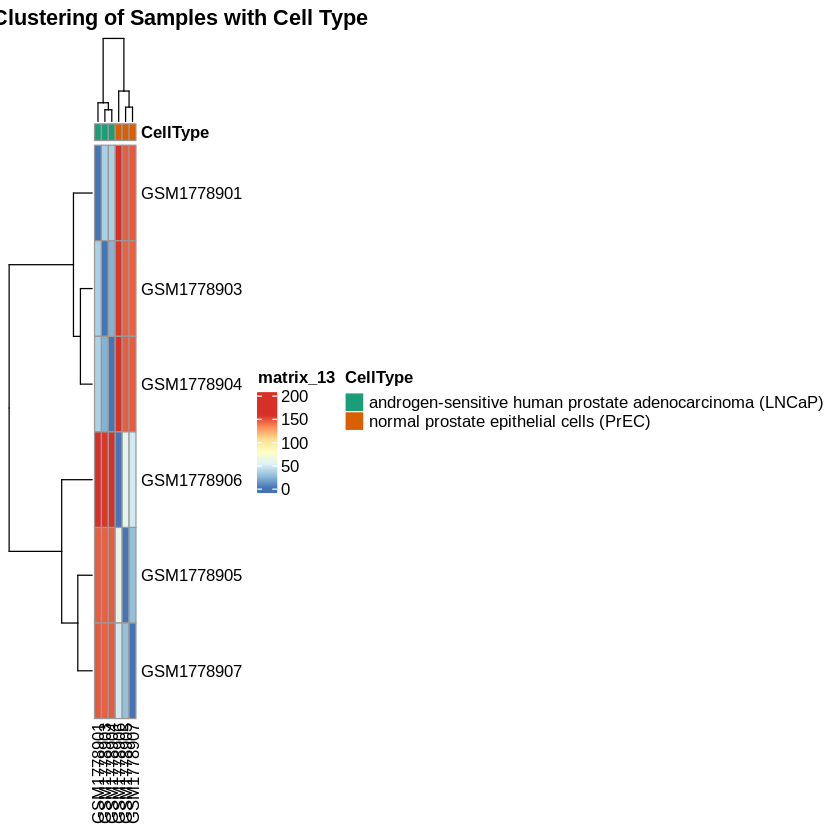

In [159]:
library(pheatmap)
library(RColorBrewer)
##pheatmap with cell.type

# 샘플 annotation 준비 (meta에서 cell.type 사용)
unique_types <- unique(meta$cell.type)
palette_colors <- RColorBrewer::brewer.pal(3, "Dark2")[1:length(unique_types)]
palette_colors
ann_colors <- list(CellType = setNames(palette_colors, unique_types))


# 샘플 간 거리 계산
sampleDists <- dist(t(assay(vsd)))
sampleDistMatrix <- as.matrix(sampleDists)
rownames(sampleDistMatrix) <- colnames(vsd)
colnames(sampleDistMatrix) <- colnames(vsd)

# # pheatmap 그리기
pheatmap(sampleDistMatrix,
         clustering_distance_rows = sampleDists,
         clustering_distance_cols = sampleDists,
         clustering_method = "complete",
         annotation_col = annotation_col,
         annotation_colors = ann_colors,
         main = "Hierarchical Clustering of Samples with Cell Type")


In [161]:
#가로로 사이즈 조정한 heatmap
pdf("/content/SNUH/sample_heatmap.pdf", width = 10, height = 6)  # width=가로, height=세로
pheatmap(sampleDistMatrix,
         clustering_distance_rows = sampleDists,
         clustering_distance_cols = sampleDists,
         clustering_method = "complete",
         annotation_col = annotation_col,
         annotation_colors = ann_colors,
         main = "Hierarchical Clustering of Samples with Cell Type")

dev.off()

agg_record_1851023224 
                    2

# 3. Data Analysis

```{r part3, eval = FALSE}
  # Run the DESeq2 pipeline (estimate size factors, gene-wise dispersion, fit the model).

  # Extract differential expression analysis results.

  # Define the thresholds (e.g., padj and |log2FC|) and report examples of significantly differentially expressed genes (DEGs).

  # You might want to include comments on the biological meaning / rationale of dispersion estimation and DEG thresholds.
```

In [257]:
#3.1 DESeq2
meta$cell.line <- factor(meta$cell.line, levels = c("PrEC", "LNCaP"))
dds <- DESeqDataSetFromMatrix(countData = expr_filtered,
                              colData = meta,
                              design = ~ cell.line)  # 분석하고자 하는 변수로 수정
dds <- DESeq(dds)

resultsNames(dds)


estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] "Intercept"               "cell.line_LNCaP_vs_PrEC"

In [266]:
res <- lfcShrink(dds,
                 coef = 'cell.line_LNCaP_vs_PrEC',
                 type = "apeglm")
res <- na.omit(res)
summary(res)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 14517 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 4478, 31%
LFC < 0 (down)     : 4853, 33%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [267]:
res[order(res$padj), ]

log2 fold change (MAP): cell.line LNCaP vs PrEC 
Wald test p-value: cell.line LNCaP vs PrEC 
DataFrame with 14517 rows and 5 columns
               baseMean log2FoldChange     lfcSE       pvalue         padj
              <numeric>      <numeric> <numeric>    <numeric>    <numeric>
ANXA2          43987.97      -12.11996  0.270651  0.00000e+00  0.00000e+00
LGALS1          6991.10       -9.63241  0.257050 2.05801e-306 1.49380e-302
NKX3.1          3999.18        6.54964  0.187454 2.24482e-267 1.08627e-263
KRT5           76427.33      -13.77121  0.398297 2.23458e-265 8.10987e-262
ANXA1           5272.91       -9.14304  0.265768 2.59054e-261 7.52138e-258
...                 ...            ...       ...          ...          ...
PDE4D          172.9109    0.001611094  0.373667     0.998933     0.999175
RP11.392E22.9   88.9653    0.000896255  0.288443     0.998968     0.999175
YBEY           107.9687    0.000387054  0.257573     0.999549     0.999686
SUMF2         1480.7707    0.001197392  0.

In [268]:
# res는 DESeq2 분석 결과 (DESeqResults 객체 또는 데이터프레임)
res_df <- as.data.frame(res)

# 기본 형식으로 저장 (탭 구분 텍스트)
write.table(res_df, file = "/content/SNUH/DESeq2_results.txt", sep = "\t", quote = FALSE, row.names = TRUE, col.names = NA)

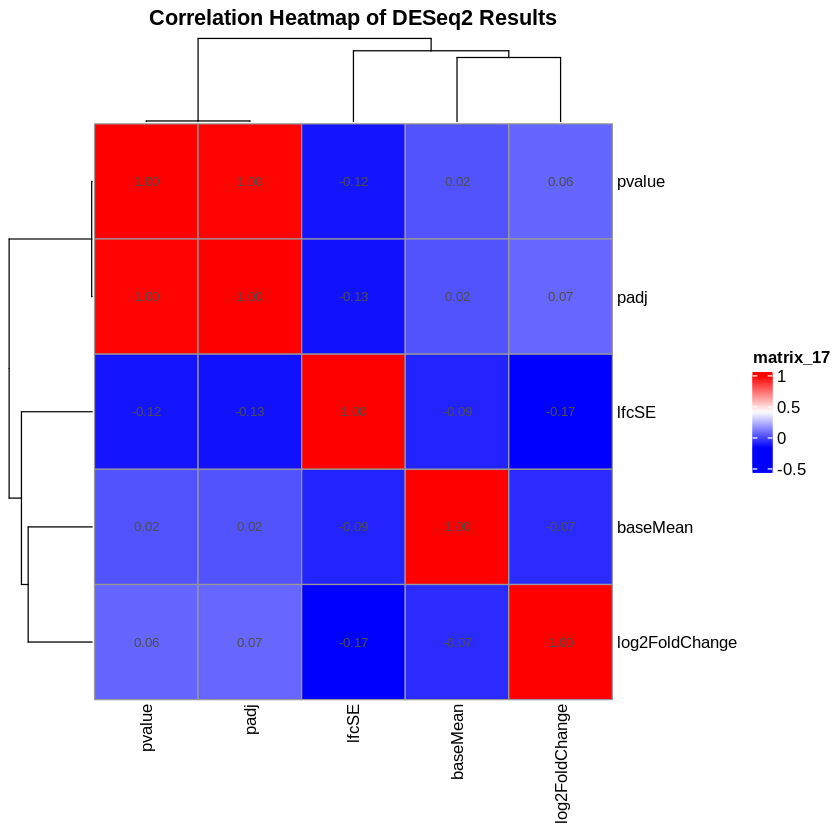

In [271]:
#결과의 상관관계 확인
# 필요한 패키지 로드
library(pheatmap)

# 상관관계 계산
cor_matrix <- cor(res_df[, c("baseMean", "log2FoldChange", "lfcSE", "pvalue", "padj")])

# 히트맵 시각화
pheatmap(cor_matrix,
         display_numbers = TRUE,
         color = colorRampPalette(c("blue", "white", "red"))(50),
         main = "Correlation Heatmap of DESeq2 Results")

Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `Value_log = case_when(...)`.
Caused by warning:
! NaNs produced”


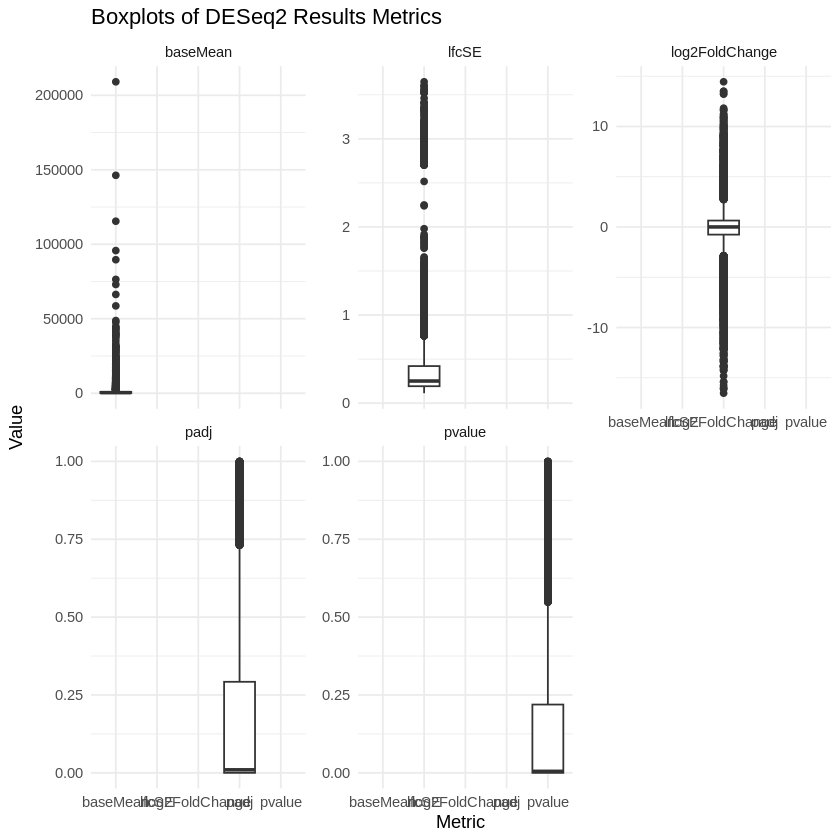

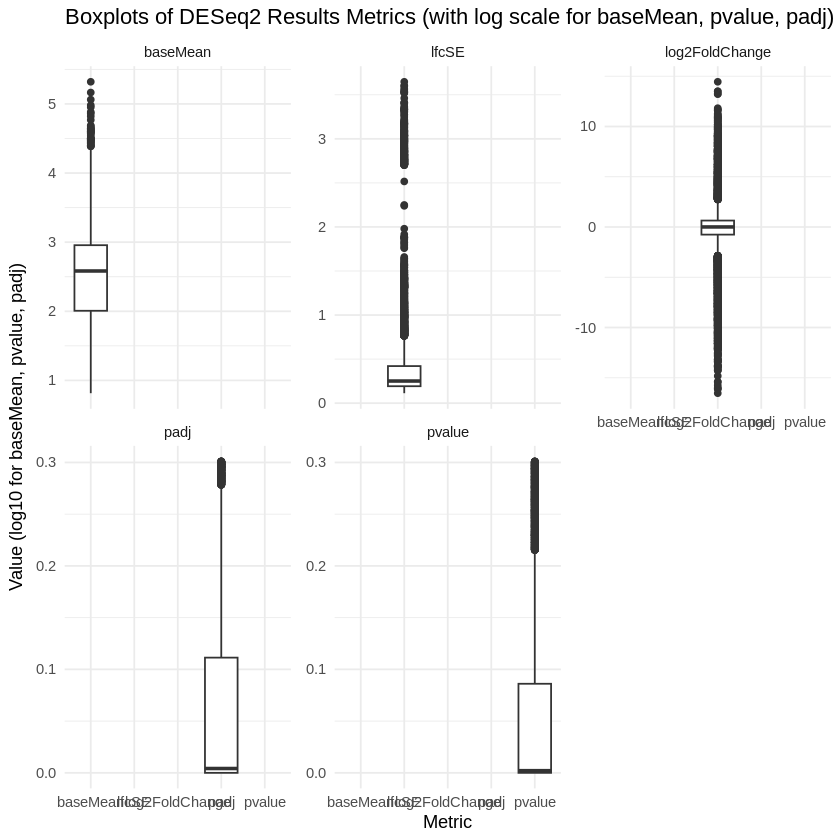

In [273]:
library(ggplot2)
library(tidyr) # for pivot_longer

# Convert res_df to a data frame if it's not already
res_df <- as.data.frame(res)

# Select the columns for boxplots
boxplot_data <- res_df[, c("baseMean", "log2FoldChange", "lfcSE", "pvalue", "padj")]

# Reshape the data for ggplot
boxplot_data_long <- pivot_longer(boxplot_data, everything(), names_to = "Metric", values_to = "Value")

# Create boxplots for each metric
ggplot(boxplot_data_long, aes(x = Metric, y = Value)) +
  geom_boxplot() +
  facet_wrap(~ Metric, scales = "free_y") + # Create separate plots for each metric with free y-scales
  theme_minimal() +
  labs(title = "Boxplots of DESeq2 Results Metrics",
       x = "Metric",
       y = "Value")

# Alternatively, plot with log scales for appropriate metrics
boxplot_data_long_log <- boxplot_data_long %>%
  mutate(Value_log = case_when(
    Metric %in% c("baseMean", "pvalue", "padj") ~ log10(Value + 1), # Add 1 to handle zeros/negative log
    TRUE ~ Value
  ))

ggplot(boxplot_data_long_log, aes(x = Metric, y = Value_log)) +
  geom_boxplot() +
  facet_wrap(~ Metric, scales = "free_y") +
  theme_minimal() +
  labs(title = "Boxplots of DESeq2 Results Metrics (with log scale for baseMean, pvalue, padj)",
       x = "Metric",
       y = "Value (log10 for baseMean, pvalue, padj)")

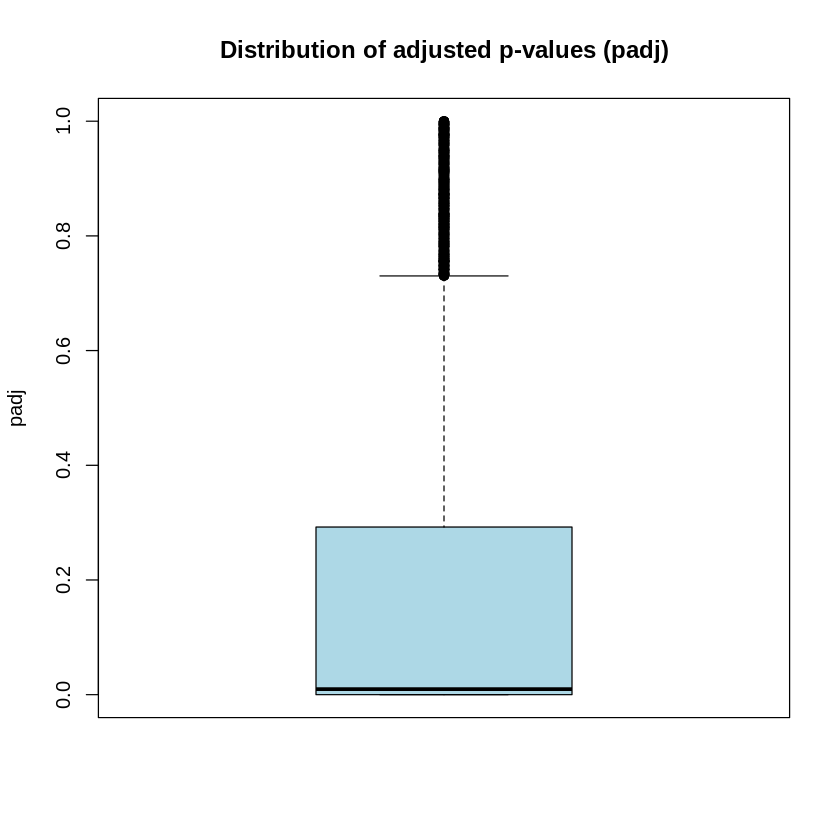

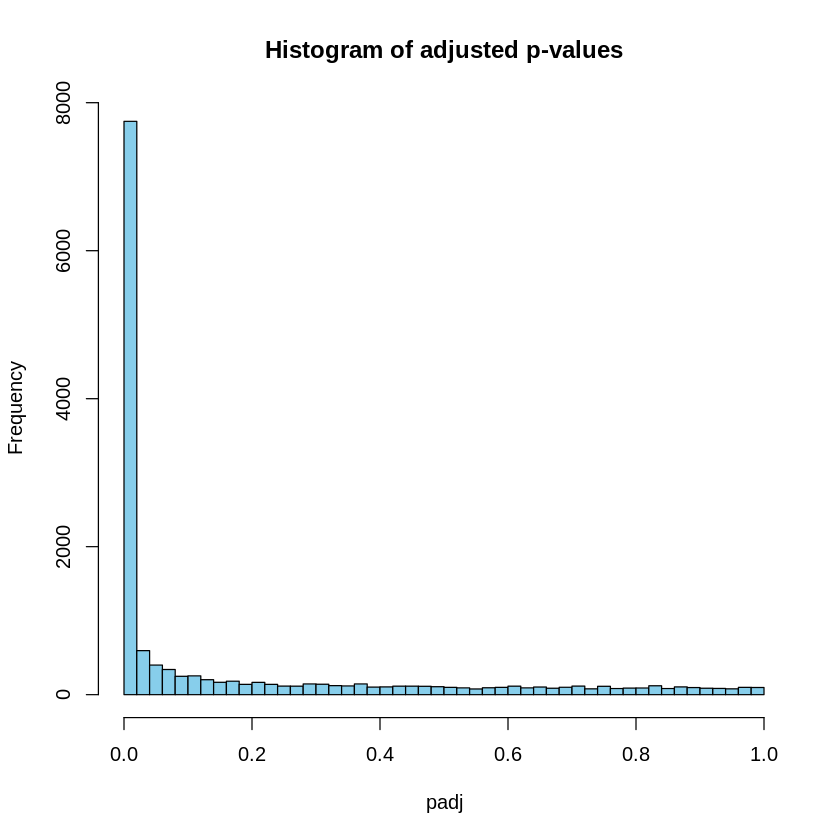

In [274]:
#padj boxplot
boxplot(res$padj, main = "Distribution of adjusted p-values (padj)",
        ylab = "padj", col = "lightblue")
#padj histogram
hist(res$padj, breaks = 50, col = "skyblue",
     main = "Histogram of adjusted p-values",
     xlab = "padj")


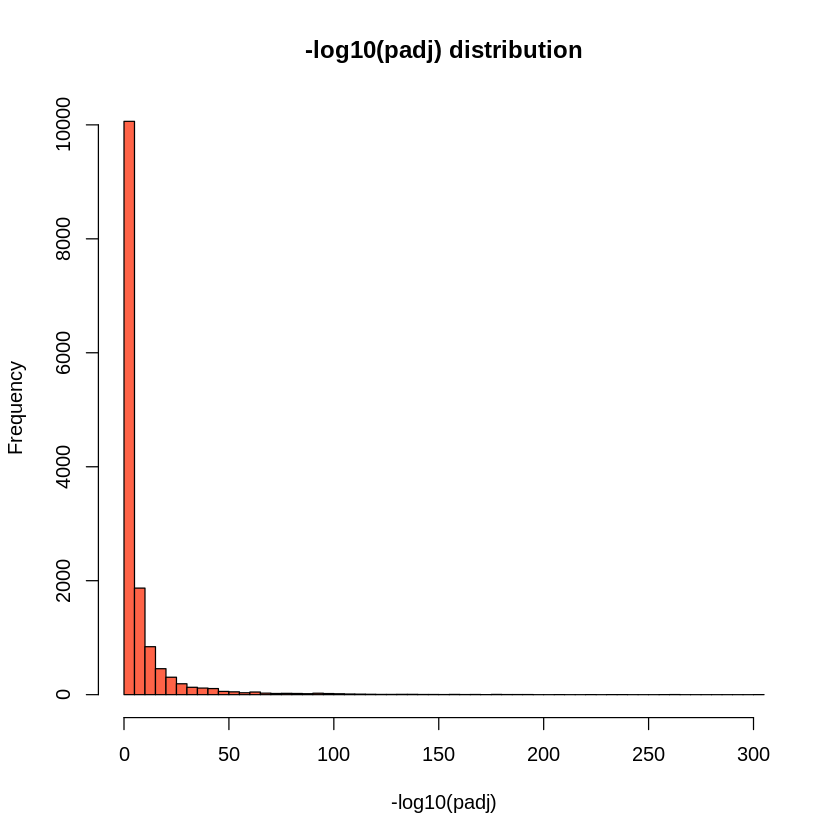

In [275]:
hist(-log10(res$padj), breaks = 50, col = "tomato",
     main = "-log10(padj) distribution",
     xlab = "-log10(padj)")


In [276]:
# Calculate the maximum value of res$baseMean
max_baseMean <- max(res$baseMean, na.rm = TRUE)
cat("Maximum baseMean:", max_baseMean, "\n")

# hist with x-axis limited by the maximum value
hist(res$baseMean, col = "tomato",
     main = "baseMean distribution",
     xlab = "baseMean",
     xlim = c(0, max_baseMean)) # Set x-axis limits

Maximum baseMean: 209091 


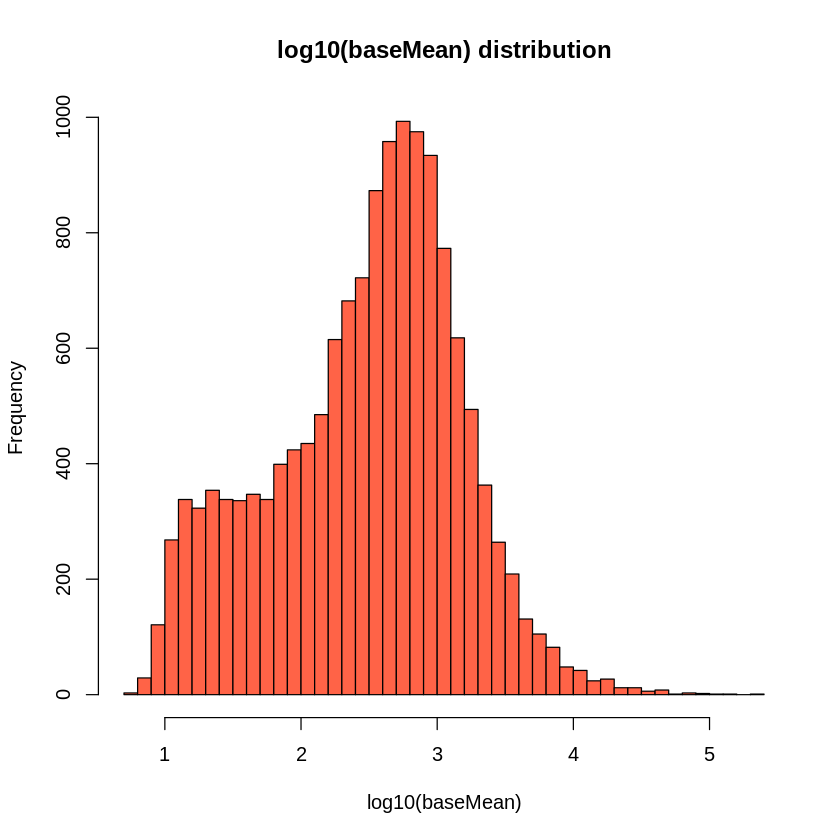

In [180]:
hist(log10(res$baseMean), breaks = 50, col = "tomato",
     main = "log10(baseMean) distribution",
     xlab = "log10(baseMean)")

  padj  lfc   up down total
1 0.05 0.58 3536 3973  7509
2 0.01 0.58 3185 3718  6903
3 0.10 0.58 3683 4071  7754
4 0.05 1.00 2408 2992  5400
5 0.01 1.00 2277 2899  5176
6 0.10 1.00 2450 3025  5475
7 0.05 1.50 1661 2267  3928
8 0.01 1.50 1633 2239  3872
9 0.10 1.50 1661 2267  3928


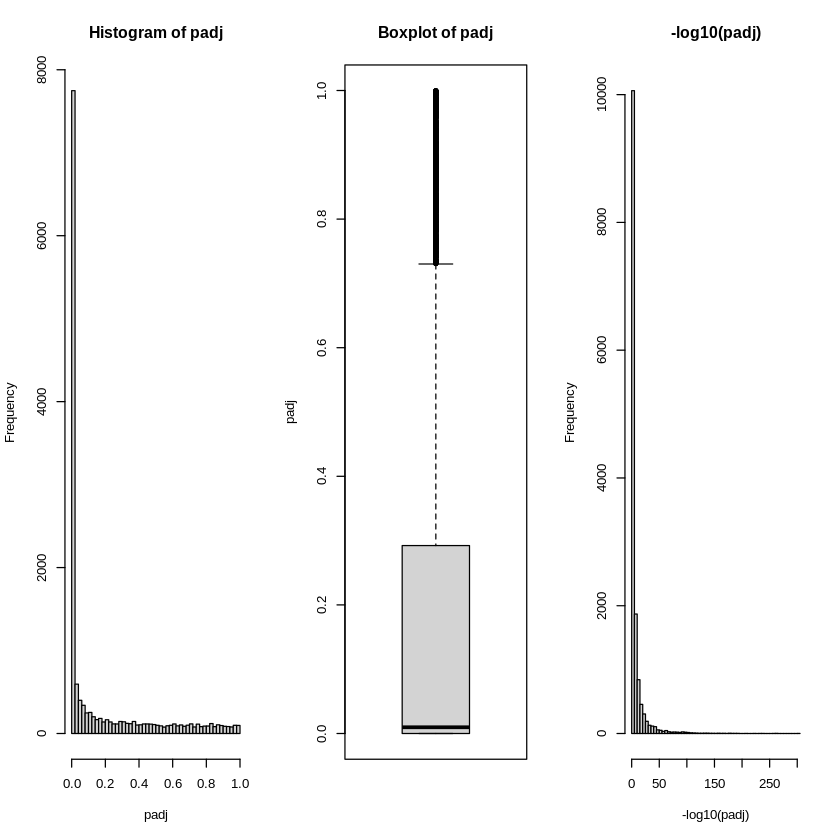

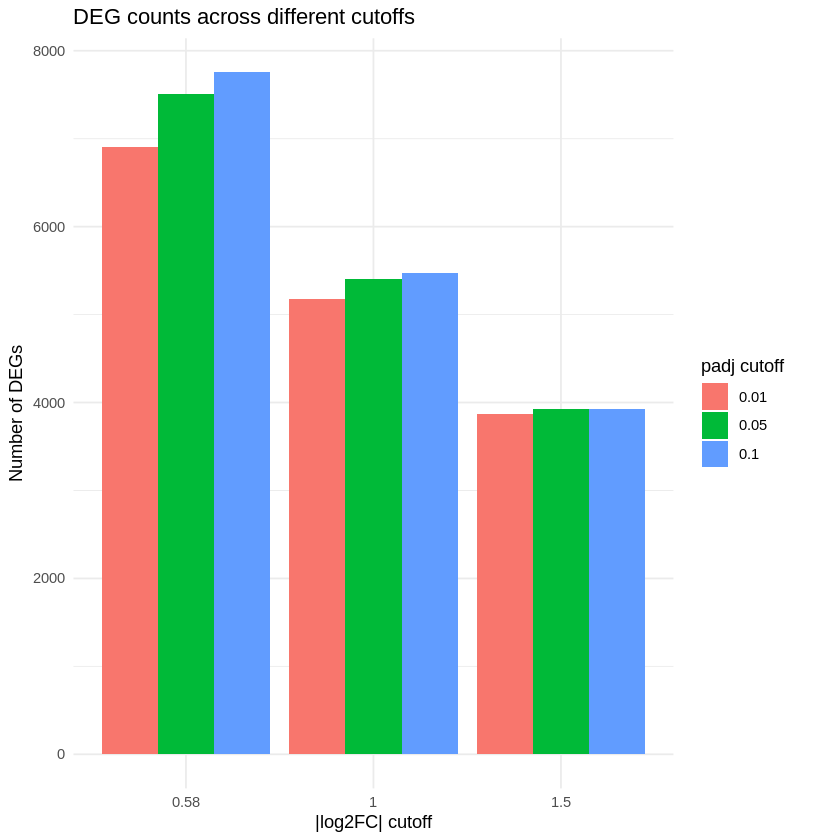

In [277]:
library(dplyr)
library(ggplot2)
library(tibble)

# res가 DESeq2 결과 객체라면 data.frame으로
res_df <- as.data.frame(res) %>% rownames_to_column("gene")

# 1) padj 분포 살펴보기
par(mfrow=c(1,3))
hist(res_df$padj, breaks=50, main="Histogram of padj", xlab="padj")
boxplot(res_df$padj, main="Boxplot of padj", ylab="padj")
hist(-log10(res_df$padj), breaks=50, main="-log10(padj)", xlab="-log10(padj)")
par(mfrow=c(1,1))

# 2) 여러 cutoff 조합에서 DEG 수 계산
padj_vals <- c(0.05, 0.01, 0.1)    # 후보 padj
lfc_vals  <- c(0.58, 1, 1.5)       # 후보 log2FC (1.5x, 2x, ~2.8x)

res_counts <- expand.grid(padj = padj_vals, lfc = lfc_vals) %>%
  mutate(
    up = mapply(function(p, l) sum(res_df$padj < p & res_df$log2FoldChange > l, na.rm=TRUE),
                padj, lfc),
    down = mapply(function(p, l) sum(res_df$padj < p & res_df$log2FoldChange < -l, na.rm=TRUE),
                  padj, lfc)
  ) %>%
  mutate(total = up + down)

# 3) 테이블 출력
print(res_counts)

# 4) 시각화: padj별, lfc별 total DEG 수
ggplot(res_counts, aes(x=factor(lfc), y=total, fill=factor(padj))) +
  geom_bar(stat="identity", position=position_dodge()) +
  labs(x="|log2FC| cutoff", y="Number of DEGs", fill="padj cutoff",
       title="DEG counts across different cutoffs") +
  theme_minimal()


In [278]:
deg2 <- subset(res, padj < 0.05 & abs(log2FoldChange) > 1 & baseMean > 50) #매우 낮은 발현 유전자는 제거
deg2


log2 fold change (MAP): cell.line LNCaP vs PrEC 
Wald test p-value: cell.line LNCaP vs PrEC 
DataFrame with 4086 rows and 5 columns
         baseMean log2FoldChange     lfcSE      pvalue        padj
        <numeric>      <numeric> <numeric>   <numeric>   <numeric>
A1BG      61.5586        1.90138  0.508289 3.79346e-05 1.05761e-04
A4GALT   114.0540       -4.81364  0.424269 1.27971e-30 2.21162e-29
AACSP1    60.3200        5.06959  0.583393 5.36198e-19 5.19279e-18
AADAT    610.8604        2.65808  0.209622 1.08739e-37 2.43605e-36
AASS     157.7113       -1.28974  0.465139 2.06115e-03 4.41453e-03
...           ...            ...       ...         ...         ...
ZSCAN26   97.8082       -1.43143  0.341902 1.00538e-05 3.04446e-05
ZSWIM4   147.5453       -2.16400  0.262237 2.97256e-17 2.57935e-16
ZSWIM5    52.2345        2.73106  0.491431 3.68253e-09 1.67374e-08
ZSWIM6   274.7007       -1.34539  0.262343 1.13139e-07 4.40096e-07
ZYX     2885.7808       -3.09990  0.165073 1.07680e-79 8.14159e-

In [279]:
# padj < 0.05, |log2FoldChange| > 1
deg <- res[which(res$padj < 0.05 & abs(res$log2FoldChange) > 1), ]

# 상위 10개 DEGs 확인
head(deg[order(deg$padj), ])

log2 fold change (MAP): cell.line LNCaP vs PrEC 
Wald test p-value: cell.line LNCaP vs PrEC 
DataFrame with 6 rows and 5 columns
        baseMean log2FoldChange     lfcSE       pvalue         padj
       <numeric>      <numeric> <numeric>    <numeric>    <numeric>
ANXA2   43987.97      -12.11996  0.270651  0.00000e+00  0.00000e+00
LGALS1   6991.10       -9.63241  0.257050 2.05801e-306 1.49380e-302
NKX3.1   3999.18        6.54964  0.187454 2.24482e-267 1.08627e-263
KRT5    76427.33      -13.77121  0.398297 2.23458e-265 8.10987e-262
ANXA1    5272.91       -9.14304  0.265768 2.59054e-261 7.52138e-258
AR       3224.39        7.99925  0.242028 9.81141e-241 2.37387e-237

In [281]:
deg_summary <- data.frame(
  log2FC = deg$log2FoldChange,
  padj = deg$padj
)
head(deg_summary, 10)

,log2FC,padj
,<dbl>,<dbl>
A1BG,1.901381,1.057609e-04
A4GALT,-4.813643,2.211621e-29
AACSP1,5.069590,5.192790e-18
AADAT,2.658079,2.436048e-36
AASS,-1.289738,4.414525e-03
AATK,1.157175,2.917282e-02
ABC13.47488600E17.1,3.986332,1.156079e-06
ABC14.864958H18.2,1.207149,2.013660e-02
ABCA1,-5.797280,1.368976e-42


In [ ]:
## Part 4: Visualization

In [282]:
library(dplyr)
library(tibble)

# =======================================================
# 1️⃣ DEG 필터링 기준 설정
# =======================================================
padj.cutoff <- 0.05
lfc.cutoff <- 0.58  # log2FC 기준 (약 1.5배 변화)

# =======================================================
# 2️⃣ Significant DEGs 선택
# =======================================================
sigDEGs <- res %>%
  as.data.frame() %>%
  rownames_to_column(var="gene") %>%
  filter(padj < padj.cutoff & abs(log2FoldChange) > lfc.cutoff)

# =======================================================
# 3️⃣ Up/Down DEG 수 계산
# =======================================================
up <- sigDEGs %>% filter(log2FoldChange > 0) %>% nrow()
down <- sigDEGs %>% filter(log2FoldChange < 0) %>% nrow()
total <- nrow(sigDEGs)

# =======================================================
# 4️⃣ 결과 표 생성
# =======================================================
deg_summary_table <- tibble(
  Comparison = "LNCaP vs PrEC",
  `Upregulated Genes` = up,
  `Downregulated Genes` = down,
  `Total Significantly Differentially Expressed Genes` = total
)

deg_summary_table


Comparison,Upregulated Genes,Downregulated Genes,Total Significantly Differentially Expressed Genes
<chr>,<int>,<int>,<int>
LNCaP vs PrEC,3536,3973,7509


In [283]:
install.packages("ggrepel")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



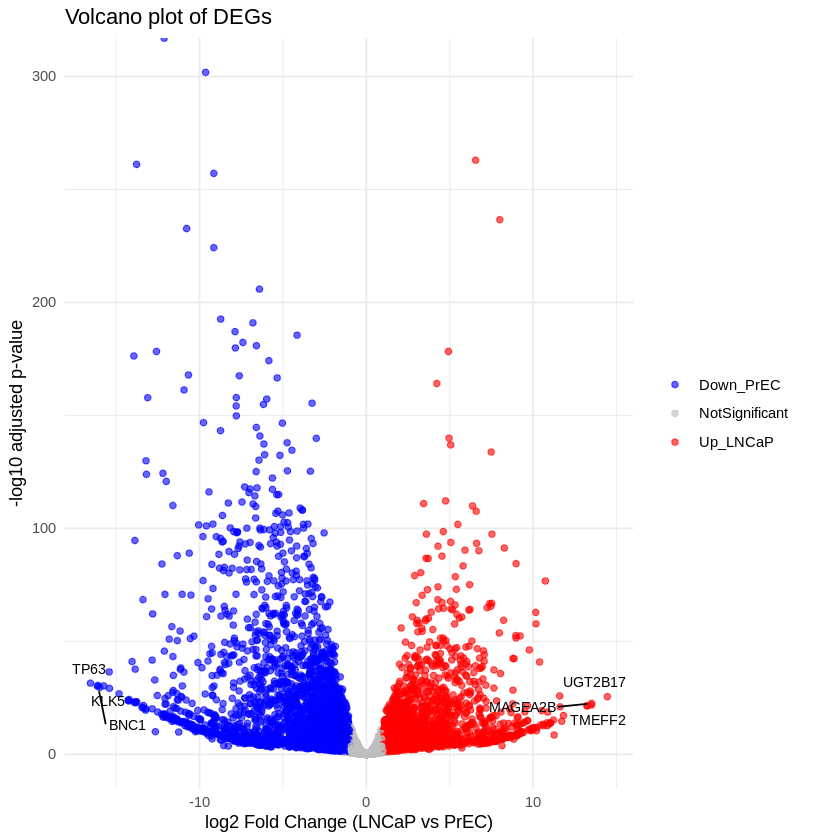

In [284]:
library(ggplot2)
library(ggrepel)

res_df <- as.data.frame(res)

# 발현 방향과 통계적 유의성을 함께 고려
res_df$regulation <- ifelse(is.na(res_df$padj) | res_df$padj >= 0.05 | abs(res_df$log2FoldChange) <= 1,
                            "NotSignificant",
                            ifelse(res_df$log2FoldChange > 0, "Up_LNCaP", "Down_PrEC"))

# 상위 3개 up-regulated, 상위 3개 down-regulated 유전자 선택
up_genes <- head(res_df[res_df$regulation=="Up_LNCaP", ][order(-res_df$log2FoldChange[res_df$regulation=="Up_LNCaP"]), ], 3)
down_genes <- head(res_df[res_df$regulation=="Down_PrEC", ][order(res_df$log2FoldChange[res_df$regulation=="Down_PrEC"]), ], 3)
label_genes <- rbind(up_genes, down_genes)

# Volcano plot
ggplot(res_df, aes(x = log2FoldChange, y = -log10(padj), color = regulation)) +
  geom_point(alpha = 0.6) +
  scale_color_manual(values = c("Up_LNCaP" = "red", "Down_PrEC" = "blue", "NotSignificant" = "grey")) +
  geom_text_repel(data = label_genes, aes(label = rownames(label_genes)),
                  size = 3, box.padding = 0.3, point.padding = 0.3, color = "black") +
  theme_minimal() +
  labs(title = "Volcano plot of DEGs",
       x = "log2 Fold Change (LNCaP vs PrEC)",
       y = "-log10 adjusted p-value") +
  theme(legend.title = element_blank())


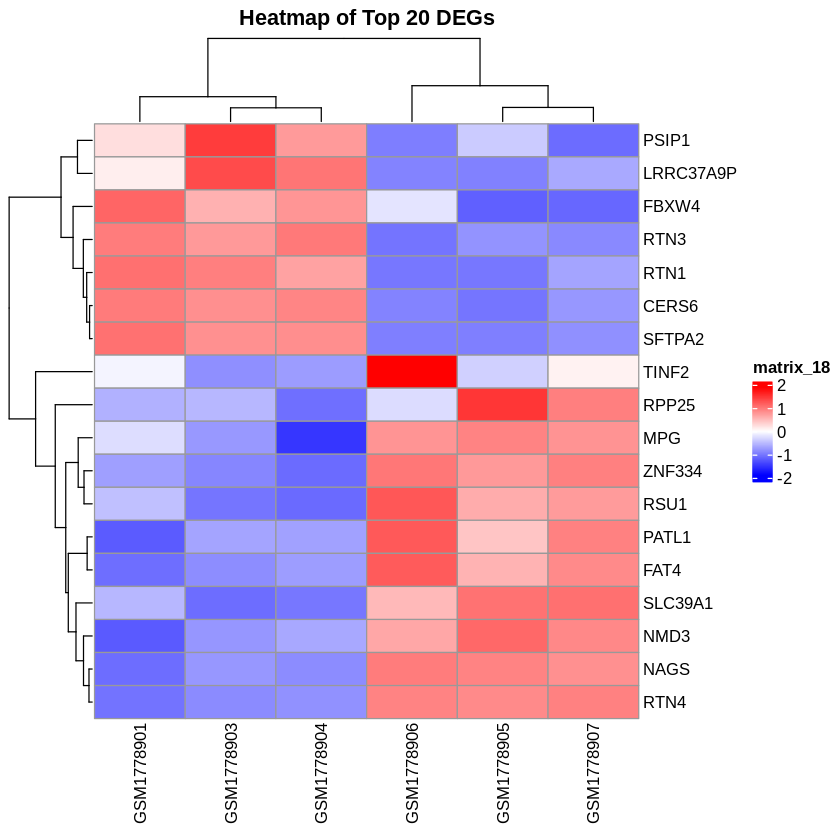

In [285]:
##heat map

library(pheatmap)

# Top 20 DEGs (절대 log2FC 기준)
top_DEGs <- head(res_df[!is.na(res_df$padj) & res_df$padj < 0.05, ][order(-abs(res_df$log2FoldChange)), ], 26)
top_gene_names <- rownames(top_DEGs)
top_gene_names <- top_gene_names[top_gene_names %in% rownames(vsd)]

# 정규화된 발현 데이터 추출
expr_top <- assay(vsd)[top_gene_names, ]  # vsd는 VST 변환된 데이터

# Heatmap 그리기
pheatmap(expr_top,
         scale = "row",  # row별 z-score로 스케일링
         cluster_rows = TRUE,
         cluster_cols = TRUE,
         show_rownames = TRUE,
         show_colnames = TRUE,
         main = "Heatmap of Top 20 DEGs",
         color = colorRampPalette(c("blue", "white", "red"))(100))


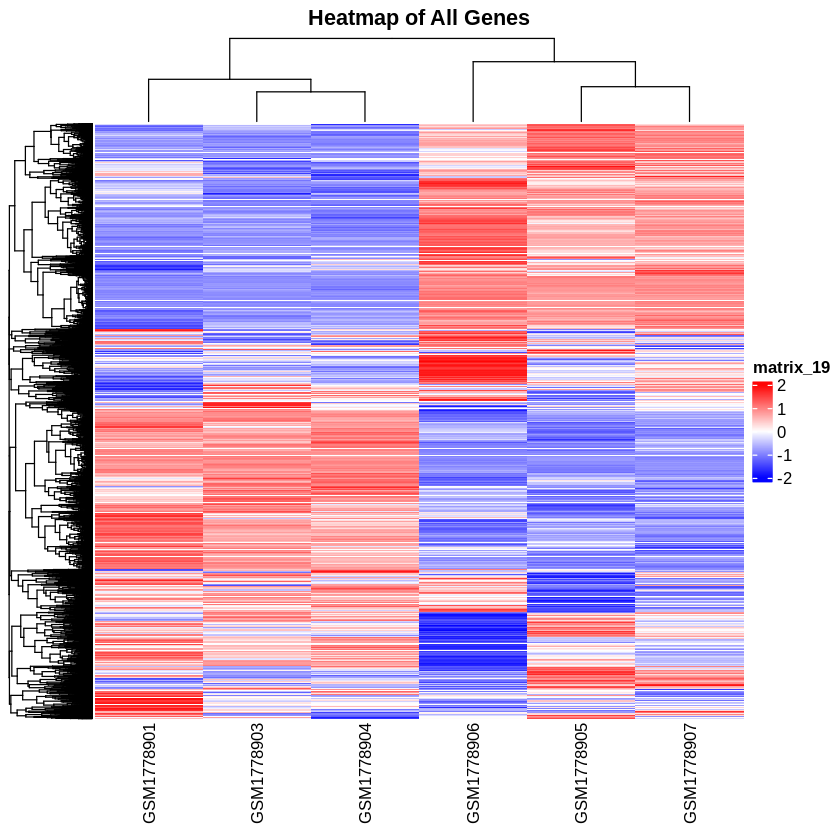

In [286]:
#전체 heatmap
# 전체 데이터 행렬 (vsd는 DESeq2 VST 변환 결과)
expr_all <- assay(vsd)

# Heatmap 그리기
pheatmap(expr_all,
         scale = "row",   # 유전자별 z-score로 스케일링
         cluster_rows = TRUE,
         cluster_cols = TRUE,
         show_rownames = FALSE,
         show_colnames = TRUE,
         main = "Heatmap of All Genes",
         color = colorRampPalette(c("blue", "white", "red"))(100))


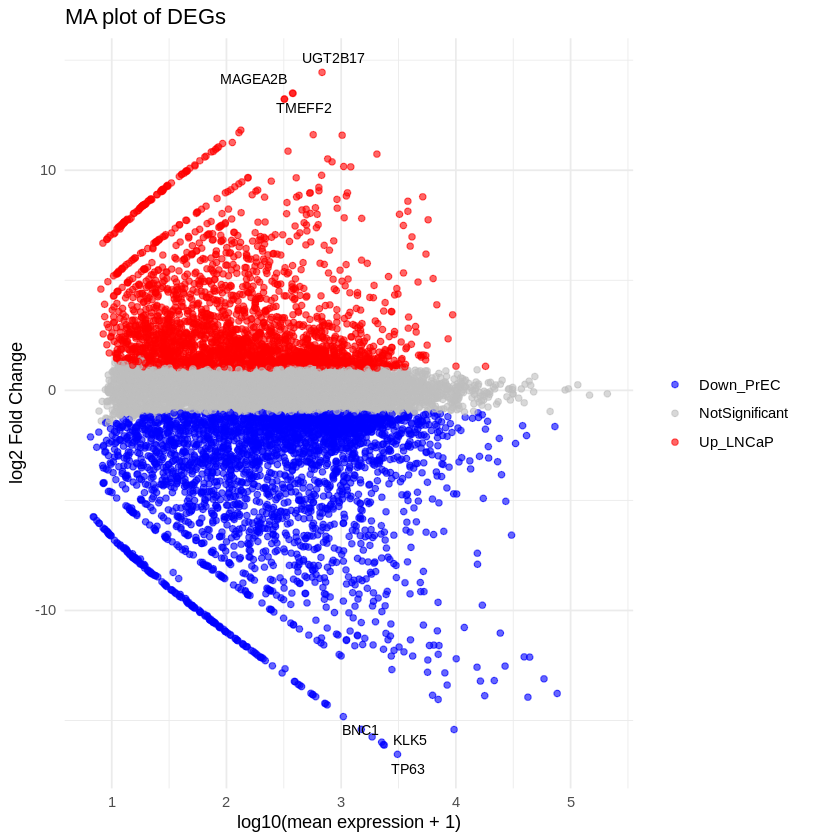

In [287]:
#MA plot
library(ggplot2)
library(ggrepel)

res_df <- as.data.frame(res)

# 발현 방향과 통계적 유의성을 함께 고려
res_df$regulation <- ifelse(is.na(res_df$padj) | res_df$padj >= 0.05 | abs(res_df$log2FoldChange) <= 1,
                            "NotSignificant",
                            ifelse(res_df$log2FoldChange > 0, "Up_LNCaP", "Down_PrEC"))

# 상위 3개 up-regulated, 상위 3개 down-regulated 유전자 선택
up_genes <- head(res_df[res_df$regulation=="Up_LNCaP", ][order(-res_df$log2FoldChange[res_df$regulation=="Up_LNCaP"]), ], 3)
down_genes <- head(res_df[res_df$regulation=="Down_PrEC", ][order(res_df$log2FoldChange[res_df$regulation=="Down_PrEC"]), ], 3)
label_genes <- rbind(up_genes, down_genes)

# MA plot
ggplot(res_df, aes(x = log10(baseMean + 1), y = log2FoldChange, color = regulation)) +
  geom_point(alpha = 0.6) +
  scale_color_manual(values = c("Up_LNCaP" = "red", "Down_PrEC" = "blue", "NotSignificant" = "grey")) +
  geom_text_repel(data = label_genes, aes(label = rownames(label_genes)),
                  size = 3, box.padding = 0.3, point.padding = 0.3, color = "black") +
  theme_minimal() +
  labs(title = "MA plot of DEGs",
       x = "log10(mean expression + 1)",
       y = "log2 Fold Change") +
  theme(legend.title = element_blank())


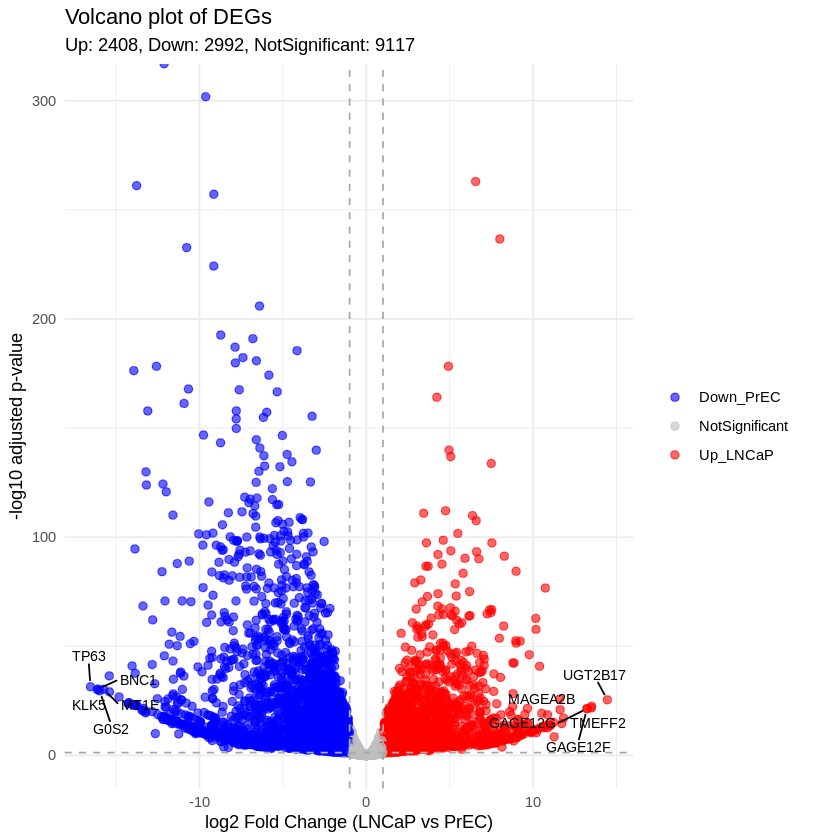

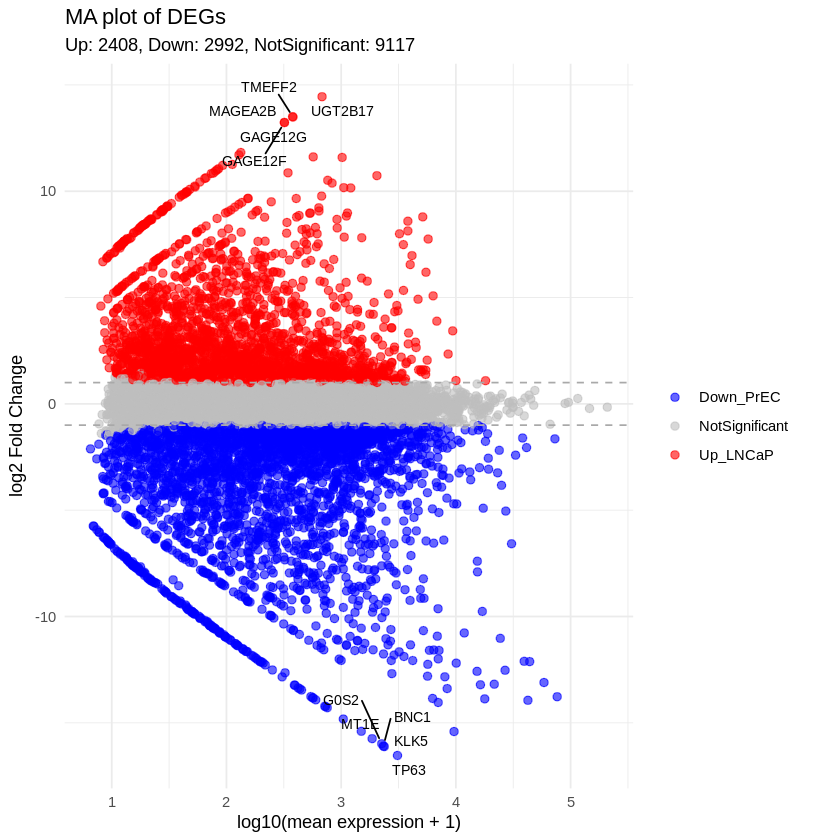

In [288]:
library(ggplot2)
library(ggrepel)

res_df <- as.data.frame(res)

# 발현 방향과 통계적 유의성을 함께 고려
res_df$regulation <- ifelse(is.na(res_df$padj) | res_df$padj >= 0.05 | abs(res_df$log2FoldChange) <= 1,
                            "NotSignificant",
                            ifelse(res_df$log2FoldChange > 0, "Up_LNCaP", "Down_PrEC"))

# 상위 5개 up/down 유전자 선택
up_genes <- head(res_df[res_df$regulation=="Up_LNCaP", ][order(-res_df$log2FoldChange[res_df$regulation=="Up_LNCaP"]), ], 5)
down_genes <- head(res_df[res_df$regulation=="Down_PrEC", ][order(res_df$log2FoldChange[res_df$regulation=="Down_PrEC"]), ], 5)
label_genes <- rbind(up_genes, down_genes)

# Volcano plot
volcano <- ggplot(res_df, aes(x = log2FoldChange, y = -log10(padj), color = regulation)) +
  geom_point(alpha = 0.6, size = 2) +
  scale_color_manual(values = c("Up_LNCaP" = "red", "Down_PrEC" = "blue", "NotSignificant" = "grey")) +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "darkgrey") +
  geom_vline(xintercept = c(-1,1), linetype = "dashed", color = "darkgrey") +
  geom_text_repel(data = label_genes, aes(label = rownames(label_genes)),
                  size = 3, box.padding = 0.3, point.padding = 0.3, color = "black") +
  theme_minimal() +
  labs(title = "Volcano plot of DEGs",
       subtitle = paste0("Up: ", sum(res_df$regulation=="Up_LNCaP"),
                         ", Down: ", sum(res_df$regulation=="Down_PrEC"),
                         ", NotSignificant: ", sum(res_df$regulation=="NotSignificant")),
       x = "log2 Fold Change (LNCaP vs PrEC)",
       y = "-log10 adjusted p-value") +
  theme(legend.title = element_blank())

# MA plot
ma <- ggplot(res_df, aes(x = log10(baseMean + 1), y = log2FoldChange, color = regulation)) +
  geom_point(alpha = 0.6, size = 2) +
  scale_color_manual(values = c("Up_LNCaP" = "red", "Down_PrEC" = "blue", "NotSignificant" = "grey")) +
  geom_hline(yintercept = c(-1,1), linetype = "dashed", color = "darkgrey") +
  geom_text_repel(data = label_genes, aes(label = rownames(label_genes)),
                  size = 3, box.padding = 0.3, point.padding = 0.3, color = "black") +
  theme_minimal() +
  labs(title = "MA plot of DEGs",
       subtitle = paste0("Up: ", sum(res_df$regulation=="Up_LNCaP"),
                         ", Down: ", sum(res_df$regulation=="Down_PrEC"),
                         ", NotSignificant: ", sum(res_df$regulation=="NotSignificant")),
       x = "log10(mean expression + 1)",
       y = "log2 Fold Change") +
  theme(legend.title = element_blank())

# 출력
volcano
ma


In [ ]:
#convert counts to integer mode
dds <- DESeqDataSetFromMatrix(countData = count_data_df,
                              colData = meta,
                              design = ~ cell.type, tidy=TRUE)

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]



In [ ]:
dds

class: DESeqDataSet 
dim: 35238 6 
metadata(1): version
assays(1): counts
rownames(35238): A1BG A1CF ... BP.2189O9.2 YR211F11.2
rowData names(0):
colnames(6): GSM1778901 GSM1778903 ... GSM1778906 GSM1778907
colData names(4): Sample_geo_accession Sample.Title cell.line cell.type

In [ ]:
BiocManager::install("AnnotationHub")
mcols(AnnotationHub::AnnotationHub()) %>%
  as_tibble(rownames = "record_id") %>%
  dplyr::filter(rdataclass == "EnsDb")

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.21 (BiocManager 1.30.26), R 4.5.1 (2025-06-13)

Installing package(s) 'AnnotationHub'

also installing the dependencies ‘png’, ‘Biostrings’, ‘filelock’, ‘plogr’, ‘KEGGREST’, ‘BiocFileCache’, ‘RSQLite’, ‘AnnotationDbi’


Old packages: 'devtools', 'systemfonts'



record_id,title,dataprovider,species,taxonomyid,genome,description,coordinate_1_based,maintainer,rdatadateadded,preparerclass,tags,rdataclass,rdatapath,sourceurl,sourcetype
<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<I<named list>>,<chr>,<chr>,<chr>,<chr>
AH53185,Ensembl 87 EnsDb for Anolis Carolinensis,Ensembl,Anolis carolinensis,28377,AnoCar2.0,Gene and protein annotations for Anolis Carolinensis based on Ensembl version 87.,1,Johannes Rainer <johannes.rainer@eurac.edu>,2017-02-07,AHEnsDbs,"EnsDb, E....",EnsDb,AHEnsDbs/v87/EnsDb.Acarolinensis.v87.sqlite,http://www.ensembl.org,ensembl
AH53186,Ensembl 87 EnsDb for Ailuropoda Melanoleuca,Ensembl,Ailuropoda melanoleuca,9646,ailMel1,Gene and protein annotations for Ailuropoda Melanoleuca based on Ensembl version 87.,1,Johannes Rainer <johannes.rainer@eurac.edu>,2017-02-07,AHEnsDbs,"EnsDb, E....",EnsDb,AHEnsDbs/v87/EnsDb.Amelanoleuca.v87.sqlite,http://www.ensembl.org,ensembl
AH53187,Ensembl 87 EnsDb for Astyanax Mexicanus,Ensembl,Astyanax mexicanus,7994,AstMex102,Gene and protein annotations for Astyanax Mexicanus based on Ensembl version 87.,1,Johannes Rainer <johannes.rainer@eurac.edu>,2017-02-07,AHEnsDbs,"EnsDb, E....",EnsDb,AHEnsDbs/v87/EnsDb.Amexicanus.v87.sqlite,http://www.ensembl.org,ensembl
AH53188,Ensembl 87 EnsDb for Anas Platyrhynchos,Ensembl,Anas platyrhynchos,8839,BGI_duck_1.0,Gene and protein annotations for Anas Platyrhynchos based on Ensembl version 87.,1,Johannes Rainer <johannes.rainer@eurac.edu>,2017-02-07,AHEnsDbs,"EnsDb, E....",EnsDb,AHEnsDbs/v87/EnsDb.Aplatyrhynchos.v87.sqlite,http://www.ensembl.org,ensembl
AH53189,Ensembl 87 EnsDb for Bos Taurus,Ensembl,Bos taurus,9913,UMD3.1,Gene and protein annotations for Bos Taurus based on Ensembl version 87.,1,Johannes Rainer <johannes.rainer@eurac.edu>,2017-02-07,AHEnsDbs,"EnsDb, E....",EnsDb,AHEnsDbs/v87/EnsDb.Btaurus.v87.sqlite,http://www.ensembl.org,ensembl
AH53190,Ensembl 87 EnsDb for Caenorhabditis Elegans,Ensembl,Caenorhabditis elegans,6239,WBcel235,Gene and protein annotations for Caenorhabditis Elegans based on Ensembl version 87.,1,Johannes Rainer <johannes.rainer@eurac.edu>,2017-02-07,AHEnsDbs,"EnsDb, E....",EnsDb,AHEnsDbs/v87/EnsDb.Celegans.v87.sqlite,http://www.ensembl.org,ensembl
AH53191,Ensembl 87 EnsDb for Canis Familiaris,Ensembl,Canis familiaris,9615,CanFam3.1,Gene and protein annotations for Canis Familiaris based on Ensembl version 87.,1,Johannes Rainer <johannes.rainer@eurac.edu>,2017-02-07,AHEnsDbs,"EnsDb, E....",EnsDb,AHEnsDbs/v87/EnsDb.Cfamiliaris.v87.sqlite,http://www.ensembl.org,ensembl
AH53192,Ensembl 87 EnsDb for Choloepus Hoffmanni,Ensembl,Choloepus hoffmanni,9358,choHof1,Gene and protein annotations for Choloepus Hoffmanni based on Ensembl version 87.,1,Johannes Rainer <johannes.rainer@eurac.edu>,2017-02-07,AHEnsDbs,"EnsDb, E....",EnsDb,AHEnsDbs/v87/EnsDb.Choffmanni.v87.sqlite,http://www.ensembl.org,ensembl
AH53193,Ensembl 87 EnsDb for Ciona Intestinalis,Ensembl,Ciona intestinalis,7719,KH,Gene and protein annotations for Ciona Intestinalis based on Ensembl version 87.,1,Johannes Rainer <johannes.rainer@eurac.edu>,2017-02-07,AHEnsDbs,"EnsDb, E....",EnsDb,AHEnsDbs/v87/EnsDb.Cintestinalis.v87.sqlite,http://www.ensembl.org,ensembl


In [ ]:
plot_total_counts(dds)

ERROR: Error in plot_total_counts(dds): could not find function "plot_total_counts"


In [ ]:
# 정규화
vsd <- vst(dds, blind=FALSE)
mean_sd_plot(vsd)

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]



ERROR: Error in mean_sd_plot(vsd): could not find function "mean_sd_plot"


  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]

using ntop=500 top features by variance



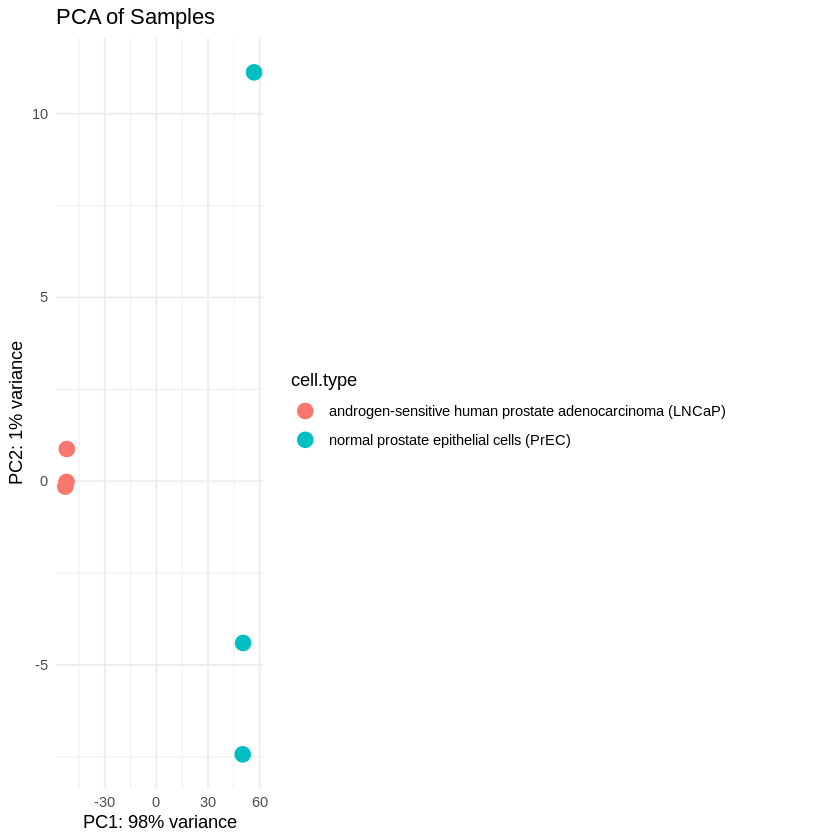

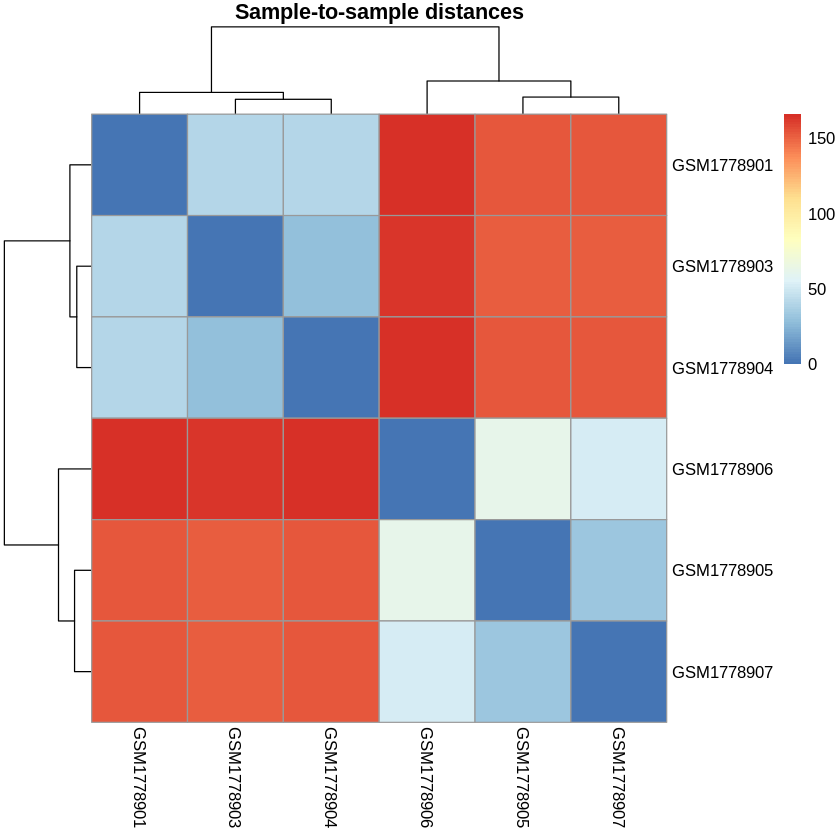

In [ ]:
# 정규화
vsd <- vst(dds, blind=FALSE)
mean_sd_plot(vsd)
# PCA 수행
pcaData <- plotPCA(vsd, intgroup="cell.type", returnData=TRUE)
percentVar <- round(100 * attr(pcaData, "percentVar"))

# PCA 시각화
ggplot(pcaData, aes(PC1, PC2, color=cell.type)) +
  geom_point(size=4) +
  xlab(paste0("PC1: ", percentVar[1], "% variance")) +
  ylab(paste0("PC2: ", percentVar[2], "% variance")) +
  ggtitle("PCA of Samples") +
  theme_minimal()

# Hierarchical clustering (sample distance heatmap)
sampleDists <- dist(t(assay(vsd)))
sampleDistMatrix <- as.matrix(sampleDists)
rownames(sampleDistMatrix) <- colnames(vsd)
colnames(sampleDistMatrix) <- colnames(vsd)

pheatmap(sampleDistMatrix,
         clustering_distance_rows = sampleDists,
         clustering_distance_cols = sampleDists,
         main = "Sample-to-sample distances")

## Part 3: Data analysis

```{r part3, eval = FALSE}

  # Run the DESeq2 pipeline (estimate size factors, gene-wise dispersion, fit the model).

  # Extract differential expression analysis results.

  # Define the thresholds (e.g., padj and |log2FC|) and report examples of significantly differentially expressed genes (DEGs).

  # You might want to include comments on the biological meaning / rationale of dispersion estimation and DEG thresholds.

```

In [ ]:
dds <- DESeqDataSetFromMatrix(countData = filtered_counts,
                              colData = meta,
                              design = ~ cell.type)  # 분석하고자 하는 변수로 수정

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]



In [ ]:
# 필터링 후 유전자 수 확인
dds <- dds[rowSums(counts(dds)) >= 10, ]

# DESeq2 분석 실행 (크기 보정, 분산 추정, 모델 적합)
dds <- DESeq(dds)

estimating size factors

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]

final dispersion estimates

fitting model and testing



In [ ]:
# 기본 대비군을 기준으로 결과 추출 (예: normal vs cancer)
res <- results(dds, contrast = c("cell.type", "normal prostate epithelial cells (PrEC)", "androgen-sensitive human prostate adenocarcinoma (LNCaP)"))

# 결과 정렬 (padj 기준)
res <- res[order(res$padj), ]

# NA 제거
res <- na.omit(res)

In [ ]:
sig_res <- subset(res, padj < 0.05 & abs(log2FoldChange) > 1)

# 상위 10개 유전자 출력
head(sig_res, 10)

log2 fold change (MLE): cell.type normal prostate epithelial cells (PrEC) vs androgen-sensitive human prostate adenocarcinoma (LNCaP) 
Wald test p-value: cell.type normal.prostate.epithelial.cells..PrEC. vs androgen.sensitive.human.prostate.adenocarcinoma..LNCaP. 
DataFrame with 10 rows and 6 columns
        baseMean log2FoldChange     lfcSE      stat       pvalue         padj
       <numeric>      <numeric> <numeric> <numeric>    <numeric>    <numeric>
BIRC8   44402.44       12.15970  0.271517   44.7843  0.00000e+00  0.00000e+00
LGALS1   7055.74        9.67285  0.258527   37.4152 2.21290e-306 1.99449e-302
KRT5    77093.75       13.83208  0.396083   34.9221 3.43026e-267 2.06113e-263
NKX3.1   3963.09       -6.51874  0.187273  -34.8088 1.79312e-265 8.08070e-262
BIRC3    5322.43        9.18389  0.266560   34.4533 4.01506e-260 1.44751e-256
BTBD8    3195.39       -7.98570  0.242750  -32.8968 2.44447e-237 7.34401e-234
SFN     11955.13       10.81929  0.331053   32.6815 2.86334e-234 7.37351e-

In [ ]:
# dds <- DESeqDataSetFromMatrix(countData = expr_df,
#                               colData = meta,
#                               design = ~ cell.type, tidy=TRUE)



Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]



## Part 4: Visualization

```{r part4, eval = FALSE}

  # Create at least two different plots, including a volcano plot, to visualize and summarize the analysis.


In [ ]:
head(dds)

class: DESeqDataSet 
dim: 6 6 
metadata(1): version
assays(4): counts mu H cooks
rownames(6): A1BG A1CF ... A2MP1 A4GALT
rowData names(22): baseMean baseVar ... deviance maxCooks
colnames(6): GSM1778901 GSM1778903 ... GSM1778906 GSM1778907
colData names(5): Sample_geo_accession Sample.Title cell.line cell.type
  sizeFactor

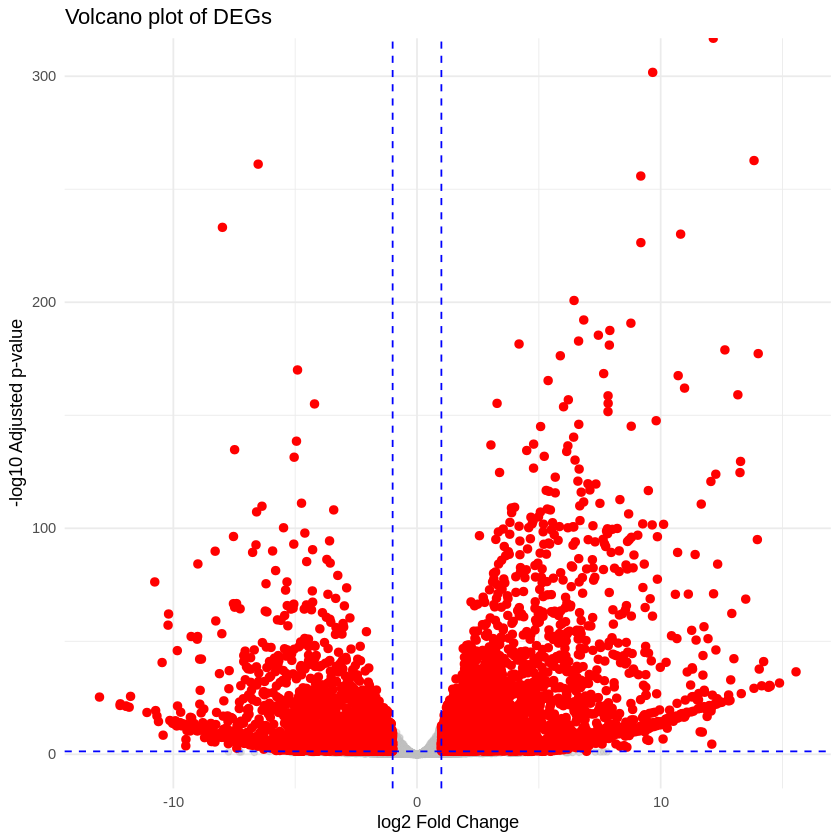

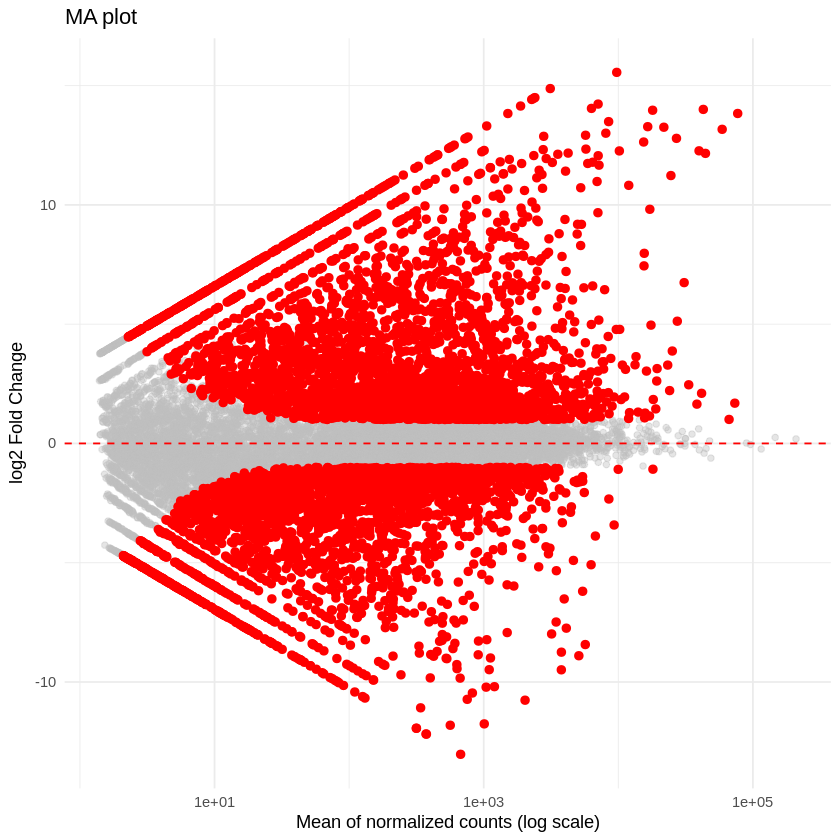

In [ ]:
# res는 DESeq2 결과 데이터프레임이라고 가정
res_df <- as.data.frame(res)

# volcano plot 그리기
ggplot(res_df, aes(x = log2FoldChange, y = -log10(padj))) +
  geom_point(alpha=0.4, size=1.5, color = "grey") +
  geom_point(data = subset(res_df, padj < 0.05 & abs(log2FoldChange) > 1),
             aes(x = log2FoldChange, y = -log10(padj)),
             color = "red", size = 2) +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "blue") +
  geom_vline(xintercept = c(-1,1), linetype = "dashed", color = "blue") +
  theme_minimal() +
  labs(title = "Volcano plot of DEGs",
       x = "log2 Fold Change",
       y = "-log10 Adjusted p-value")

# MA plot 그리기
ggplot(res_df, aes(x = baseMean, y = log2FoldChange)) +
  geom_point(alpha=0.4, size=1.5, color = "grey") +
  geom_point(data = subset(res_df, padj < 0.05 & abs(log2FoldChange) > 1),
             aes(x = baseMean, y = log2FoldChange),
             color = "red", size = 2) +
  scale_x_log10() +
  geom_hline(yintercept = 0, color = "red", linetype = "dashed") +
  theme_minimal() +
  labs(title = "MA plot",
       x = "Mean of normalized counts (log scale)",
       y = "log2 Fold Change")

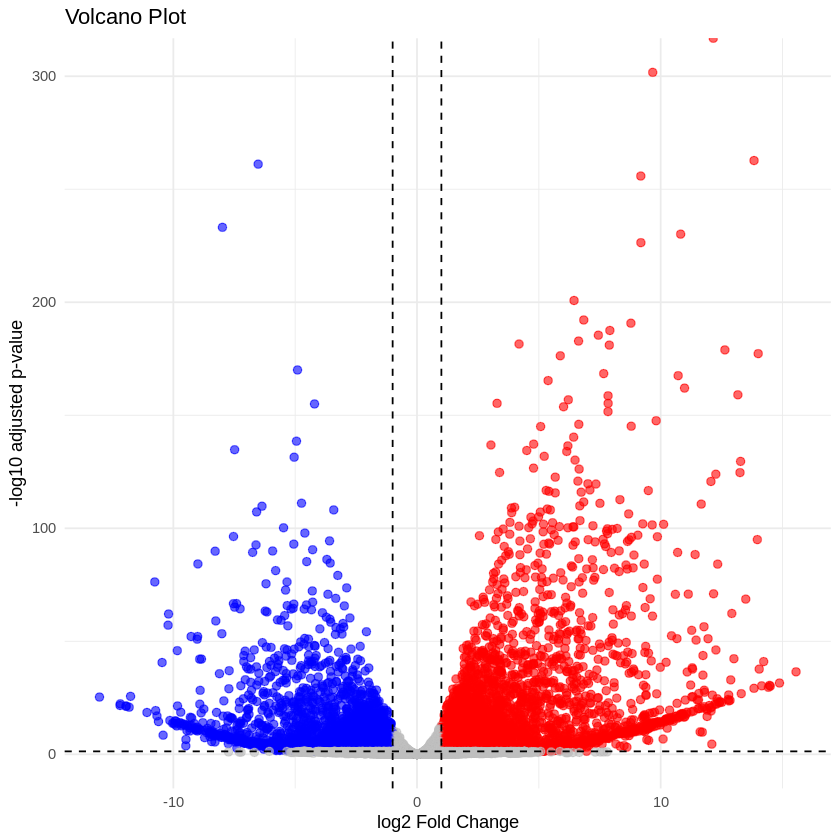

In [ ]:
library(ggplot2)

# res가 이미 data.frame 또는 DataFrame 형태라 가정
res_df <- as.data.frame(res)

# NA 제거
res_df <- na.omit(res_df)

# 색상 기준: padj < 0.05 & |log2FoldChange| > 1 인 경우에 색 지정
res_df$color <- "grey"  # 기본 색: 회색
res_df$color[res_df$padj < 0.05 & res_df$log2FoldChange > 1] <- "red"   # upregulated
res_df$color[res_df$padj < 0.05 & res_df$log2FoldChange < -1] <- "blue" # downregulated

# volcano plot 그리기
ggplot(res_df, aes(x = log2FoldChange, y = -log10(padj), color = color)) +
  geom_point(alpha = 0.6, size = 2) +
  scale_color_identity() +  # 색상을 직접 사용
  geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "black") +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "black") +
  theme_minimal() +
  labs(title = "Volcano Plot",
       x = "log2 Fold Change",
       y = "-log10 adjusted p-value")


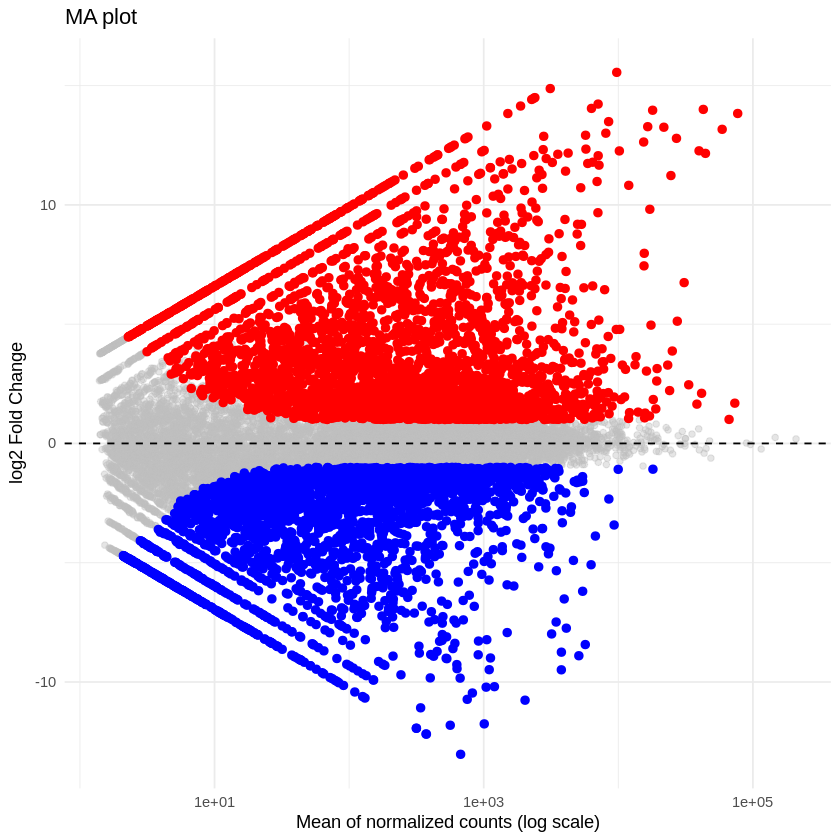

In [ ]:
ggplot(res_df, aes(x = baseMean, y = log2FoldChange)) +
  geom_point(alpha = 0.4, size = 1.5, color = "grey") +  # 기본 회색 점들
  geom_point(data = subset(res_df, padj < 0.05 & log2FoldChange > 1),
             aes(x = baseMean, y = log2FoldChange),
             color = "red", size = 2) +  # upregulated 빨강 점
  geom_point(data = subset(res_df, padj < 0.05 & log2FoldChange < -1),
             aes(x = baseMean, y = log2FoldChange),
             color = "blue", size = 2) + # downregulated 파랑 점
  scale_x_log10() +
  geom_hline(yintercept = 0, color = "black", linetype = "dashed") +
  theme_minimal() +
  labs(title = "MA plot",
       x = "Mean of normalized counts (log scale)",
       y = "log2 Fold Change")
